# Multi-Frame OCR Consensus and Evidence-Based Abstention

This notebook consumes the per-frame OCR output from `05_license_plate_detection_ocr.ipynb`. It tests whether independent observations of the same plate agree.

**Important:** multiple preprocessing variants from one video frame are not independent observations. This notebook first keeps one prediction per frame for a chosen engine/variant, then evaluates exact-string agreement. Confidence thresholds are experiment settings, not universal probabilities.

In [1]:
from pathlib import Path
from collections import Counter
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PREDICTIONS_CSV = Path("outputs/ocr_predictions_by_frame.csv")
OUTPUT_DIR = Path("outputs")

assert PREDICTIONS_CSV.is_file(), "Run notebook 05 first or set PREDICTIONS_CSV to its output CSV."
predictions_df=pd.read_csv(PREDICTIONS_CSV)
display(predictions_df.head())

,frame_number,timestamp_seconds,crop_path,engine,variant,text,confidence,latency_ms,num_text_regions
0,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,PaddleOCR,raw_upscaled,NaN,0.000000,0.2768,0
1,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,EasyOCR,raw_upscaled,NaN,0.000000,168.3307,0
2,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,PaddleOCR,clahe,NaN,0.000000,0.0658,0
3,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,EasyOCR,clahe,AJSL,0.248628,278.6995,2
4,66,2.2,outputs\ranked_crops\frame_000002200_det_0.jpg,PaddleOCR,gray,NaN,0.000000,0.2443,0


## Choose the OCR engine and preprocessing variant

Select one combination at a time. Do not mix PaddleOCR and EasyOCR confidence scores as though they were calibrated on the same scale. Can repeat the experiment for other combinations and compare the abstention/readability results.

In [47]:
print("Engines:",sorted(predictions_df.engine.dropna().unique()))
print("Variants:",sorted(predictions_df.variant.dropna().unique()))

ENGINE = "EasyOCR"
VARIANT = "clahe"
MIN_CONFIDENCE = 0.20
MIN_READABLE_FRAMES = 3
MIN_AGREEMENT_RATIO = 0.60

selected=predictions_df[(predictions_df.engine==ENGINE)&(predictions_df.variant==VARIANT)].copy()
assert len(selected), "No rows for this engine/variant. Check notebook 05 output."

selected=selected.sort_values("timestamp_seconds")
selected["text"] = selected.text.fillna("").astype(str)
selected["normalized_text"] = selected.text.map(lambda x: re.sub(r"[^A-Z0-9]","",x.upper()))
selected["confidence"] = pd.to_numeric(selected.confidence,errors="coerce").fillna(0.0)

# There should be one row per frame for a given engine/variant. Keep highest confidence if duplicates exist.
selected=selected.sort_values("confidence",ascending=False).drop_duplicates("frame_number").sort_values("timestamp_seconds")
display(selected[["frame_number","timestamp_seconds","text","confidence","crop_path"]])

Engines: ['EasyOCR', 'PaddleOCR']
Variants: ['adaptive', 'clahe', 'gray', 'raw_upscaled']


,frame_number,timestamp_seconds,text,confidence,crop_path
3,66,2.2,AJSL,0.248628,outputs\ranked_crops\frame_000002200_det_0.jpg
11,810,27.0,00460,0.138977,outputs\ranked_crops\frame_000027000_det_0.jpg
19,822,27.4,EZAOU560,0.039144,outputs\ranked_crops\frame_000027400_det_1.jpg
27,852,28.4,47,0.131085,outputs\ranked_crops\frame_000028400_det_0.jpg
35,870,29.0,,0.000000,outputs\ranked_crops\frame_000029000_det_0.jpg
43,882,29.4,,0.000000,outputs\ranked_crops\frame_000029400_det_2.jpg
51,906,30.2,,0.000000,outputs\ranked_crops\frame_000030200_det_1.jpg
59,924,30.8,2741432,0.052387,outputs\ranked_crops\frame_000030800_det_0.jpg


## Visualize the evidence across frames

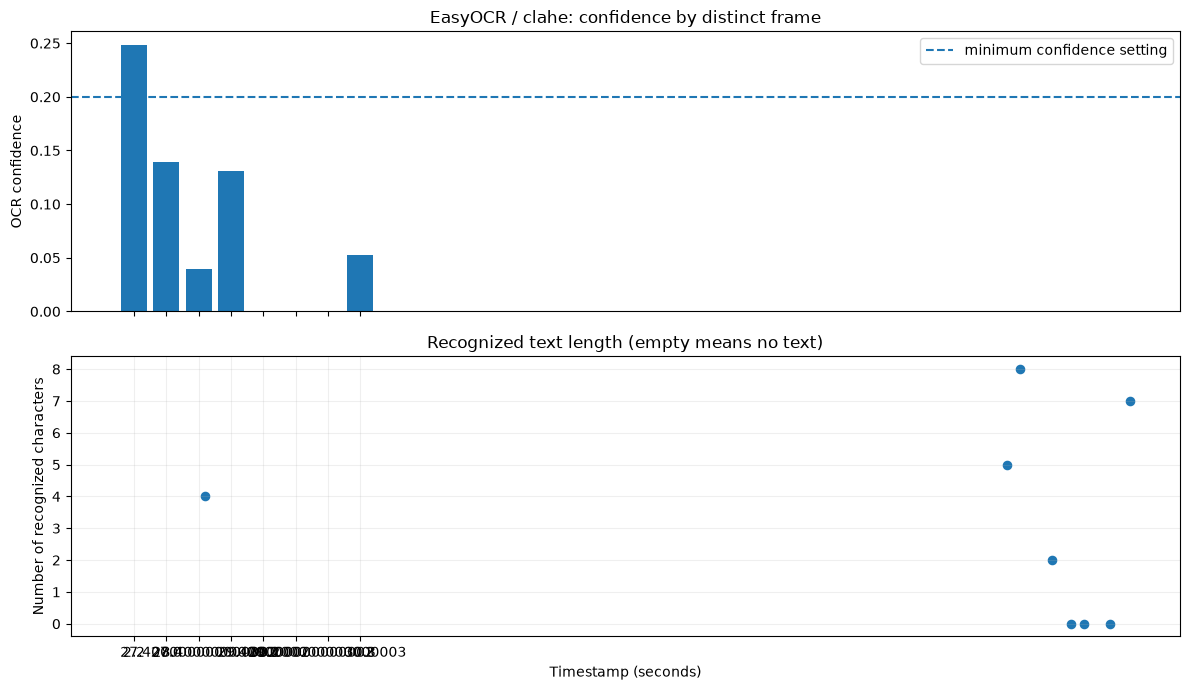

In [48]:
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)

axes[0].bar(selected.timestamp_seconds.astype(str),selected.confidence)
axes[0].axhline(MIN_CONFIDENCE,linestyle="--",label="minimum confidence setting")
axes[0].set_ylabel("OCR confidence")
axes[0].legend()
axes[0].set_title(f"{ENGINE} / {VARIANT}: confidence by distinct frame")

axes[1].scatter(selected.timestamp_seconds,selected.normalized_text.map(lambda x: len(x)),s=35)
axes[1].set(xlabel="Timestamp (seconds)",ylabel="Number of recognized characters",title="Recognized text length (empty means no text)")
axes[1].grid(alpha=.2)

plt.tight_layout()
plt.show()

## Implement a conservative exact-string consensus experiment

This baseline requires a minimum number of readable distinct frames, a minimum agreement ratio, and confidence above the selected engine's threshold. It does not fill missing characters, use registration-format assumptions, or choose a likely-looking alternative.

In [49]:
def consensus_experiment(frame_rows):
    readable=[]
    for _, row in frame_rows.iterrows():
        text=row.normalized_text
        conf=float(row.confidence)
        
        if text and conf>=MIN_CONFIDENCE:
            readable.append({"frame_number":int(row.frame_number),"text":text,"confidence":conf})
    
    if len(readable)<MIN_READABLE_FRAMES:
        return {"status":"ABSTAIN","plate_text":None,"reason":"too few readable distinct frames",
                "readable_frames":len(readable),"agreement_ratio":0.0,"mean_confidence":0.0}
    
    counts=Counter(x["text"] for x in readable)
    candidate,votes=counts.most_common(1)[0]
    agreeing=[x for x in readable if x["text"]==candidate]
    agreement=votes/len(readable)
    mean_conf=float(np.mean([x["confidence"] for x in agreeing]))
    
    if agreement<MIN_AGREEMENT_RATIO:
        status,reason,output="ABSTAIN","conflicting frame predictions",None
    else:
        status,reason,output="CANDIDATE","exact-string agreement passed experiment thresholds",candidate
    
    return {"status":status,"plate_text":output,"candidate_for_review":candidate,
            "reason":reason,"readable_frames":len(readable),"agreement_ratio":agreement,
            "mean_confidence":mean_conf,"votes":votes,"total_readable":len(readable)}

result=consensus_experiment(selected)
print(result)

{'status': 'ABSTAIN', 'plate_text': None, 'reason': 'too few readable distinct frames', 'readable_frames': 1, 'agreement_ratio': 0.0, 'mean_confidence': 0.0}


## Inspect disagreement instead of hiding it

,normalized_text,frames,mean_confidence,first_seen,last_seen
3,AJSL,1,0.248628,2.2,2.2
0,00460,1,0.138977,27.0,27.0
2,47,1,0.131085,28.4,28.4
1,2741432,1,0.052387,30.8,30.8
4,EZAOU560,1,0.039144,27.4,27.4


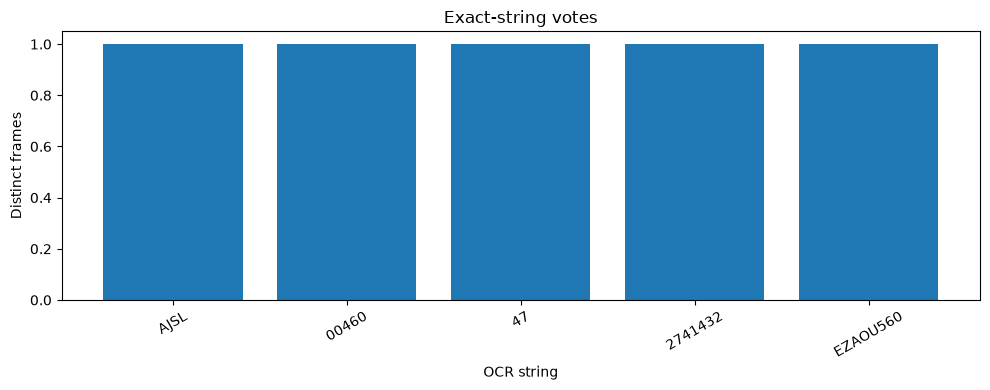

In [50]:
vote_counts=selected[selected.normalized_text!=""].groupby("normalized_text").agg(
    frames=("frame_number","nunique"),mean_confidence=("confidence","mean"),
    first_seen=("timestamp_seconds","min"),last_seen=("timestamp_seconds","max")).reset_index()
vote_counts=vote_counts.sort_values(["frames","mean_confidence"],ascending=False)
display(vote_counts)

if len(vote_counts):
    plt.figure(figsize=(10,4))
    
    plt.bar(vote_counts.normalized_text,vote_counts.frames)
    plt.xlabel("OCR string")
    plt.ylabel("Distinct frames")
    plt.title("Exact-string votes")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("No non-empty OCR predictions were produced.")

## Evaluate OCR against manually verified crop-level labels

The file `ground_truth/ocr_ground_truth.csv` contains labels manually transcribed by the reviewer from the five selected crops. Each crop is evaluated separately: do not assume detections from nearby timestamps show the same complete plate. Spaces and hyphens are removed only for comparison; the original label is retained in the CSV.

Add more independently verified crops to this CSV as you inspect them. Leave uncertain crops out rather than guessing their characters.

,crop_filename,ground_truth,text,confidence,is_exact_match,edit_distance,cer,character_accuracy
0,frame_000027000_det_0.jpg,00460,00460,0.138977,True,0,0.000,1.000
1,frame_000027400_det_1.jpg,27A - 00460,EZAOU560,0.039144,False,5,0.625,0.375
2,frame_000028400_det_0.jpg,27A 115 17,47,0.131085,False,7,0.875,0.125
3,frame_000029400_det_2.jpg,27A 115 17,,0.000000,False,8,1.000,0.000
4,frame_000030800_det_0.jpg,27A - 12432,2741432,0.052387,False,2,0.250,0.750


,engine,variant,evaluated_crops,exact_match_accuracy,non_empty_prediction_rate,false_readable_rate,abstention_rate,mean_character_error_rate,mean_character_accuracy
0,EasyOCR,clahe,5,0.2,0.8,0.6,0.2,0.55,0.45


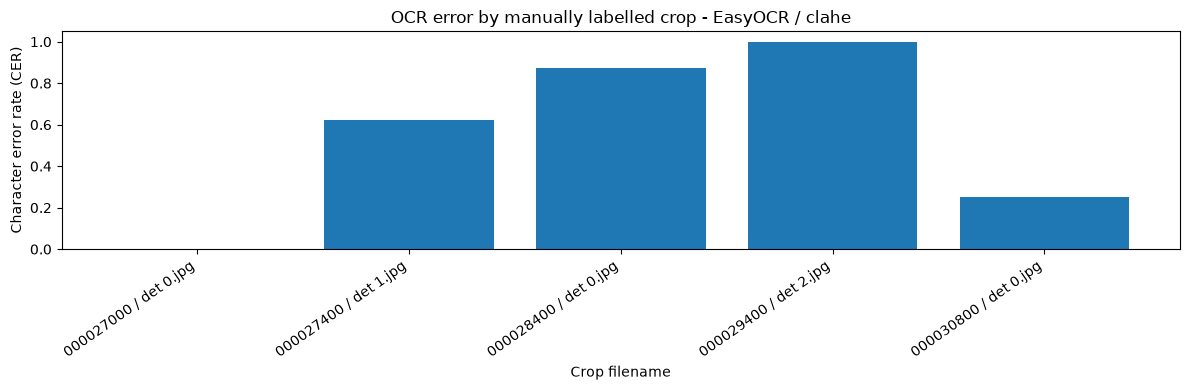

Saved crop-level evaluation and summary metrics in: outputs
Saved: outputs\multi_frame_consensus_result.csv


In [51]:
GROUND_TRUTH_CSV = Path("ground_truth/ocr_ground_truth.csv")
assert GROUND_TRUTH_CSV.is_file(), f"Ground-truth file not found: {GROUND_TRUTH_CSV}"

gt_df = pd.read_csv(GROUND_TRUTH_CSV).dropna(subset=["crop_filename", "ground_truth"])
gt_df["crop_filename"] = gt_df["crop_filename"].astype(str).map(lambda x: Path(x).name)
gt_df["ground_truth_normalized"] = gt_df["ground_truth"].map(
    lambda x: re.sub(r"[^A-Z0-9]", "", str(x).upper())
)

# Use the filename, not timestamp alone: different detections at the same time may be different crops.
eval_df = selected.copy()
eval_df["crop_filename"] = eval_df["crop_path"].fillna("").astype(str).map(lambda x: Path(x).name)
eval_df = eval_df.merge(gt_df[["crop_filename", "ground_truth", "ground_truth_normalized"]],
                        on="crop_filename", how="inner")

def edit_distance(a, b):
    """Levenshtein distance, implemented here to keep the notebook self-contained."""
    previous = list(range(len(b) + 1))
    for i, ca in enumerate(a, start=1):
        current = [i]
        for j, cb in enumerate(b, start=1):
            current.append(min(current[-1] + 1, previous[j] + 1,
                               previous[j - 1] + (ca != cb)))
        previous = current
    return previous[-1]

if eval_df.empty:
    print("No overlap between selected OCR rows and the ground-truth crop filenames.")
    print("Check PREDICTIONS_CSV and the crop_filename values in the ground-truth CSV.")
else:
    eval_df["prediction_normalized"] = eval_df["normalized_text"].fillna("")
    eval_df["is_exact_match"] = eval_df.apply(
        lambda r: bool(r.prediction_normalized) and
                  r.prediction_normalized == r.ground_truth_normalized, axis=1)
    eval_df["edit_distance"] = eval_df.apply(
        lambda r: edit_distance(r.ground_truth_normalized, r.prediction_normalized), axis=1)
    eval_df["cer"] = eval_df.apply(
        lambda r: r.edit_distance / max(1, len(r.ground_truth_normalized)), axis=1)
    eval_df["character_accuracy"] = 1 - eval_df["cer"]
    eval_df["non_empty_prediction"] = eval_df.prediction_normalized.str.len() > 0
    eval_df["false_readable"] = eval_df.non_empty_prediction & ~eval_df.is_exact_match

    display(eval_df[["crop_filename", "ground_truth", "text", "confidence",
                     "is_exact_match", "edit_distance", "cer", "character_accuracy"]])

    exact_match_accuracy = float(eval_df.is_exact_match.mean())
    non_empty_rate = float(eval_df.non_empty_prediction.mean())
    false_readable_rate = float(eval_df.false_readable.mean())
    mean_cer = float(eval_df.cer.mean())
    mean_character_accuracy = float(eval_df.character_accuracy.mean())
    abstention_rate = float((~eval_df.non_empty_prediction).mean())

    metrics = pd.DataFrame([{
        "engine": ENGINE, "variant": VARIANT, "evaluated_crops": len(eval_df),
        "exact_match_accuracy": exact_match_accuracy,
        "non_empty_prediction_rate": non_empty_rate,
        "false_readable_rate": false_readable_rate,
        "abstention_rate": abstention_rate,
        "mean_character_error_rate": mean_cer,
        "mean_character_accuracy": mean_character_accuracy,
    }])
    display(metrics)

    # Visual comparison: exact match vs incorrect/empty output for each crop.
    plot_labels = eval_df.crop_filename.map(lambda x: x.replace("frame_", "").replace("_det_", " / det "))
    
    plt.figure(figsize=(12, 4))
    plt.bar(plot_labels, eval_df.cer)
    plt.ylabel("Character error rate (CER)")
    plt.xlabel("Crop filename")
    plt.title(f"OCR error by manually labelled crop - {ENGINE} / {VARIANT}")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

    eval_df.to_csv(OUTPUT_DIR / "ocr_ground_truth_evaluation.csv", index=False)
    metrics.to_csv(OUTPUT_DIR / "ocr_ground_truth_metrics.csv", index=False)
    print("Saved crop-level evaluation and summary metrics in:", OUTPUT_DIR)

pd.DataFrame([{"engine":ENGINE,"variant":VARIANT,**result}]).to_csv(
    OUTPUT_DIR/"multi_frame_consensus_result.csv", index=False)
print("Saved:", OUTPUT_DIR/"multi_frame_consensus_result.csv")